#  $${HOMEWORK \ 5}$$


**Alumno:** Aceves Maya Christopher Daniel

**Asignatura:** Temas selectos de ingenieria

---
**Tarea 5:**

$$ regresión\ polinomial  \ y \ métricas \ de \ clasificación $$

---

Fecha: 22/10/2026

Profesor: Dr. Moises  Velasco  Lozano

##1. Introducción y Teoría ##
En el estudio de sistemas energéticos del subsuelo y geociencias, las propiedades petrofísicas raramente presentan un comportamiento perfectamente lineal frente a la respuesta de producción de un pozo.  
El aprendizaje supervisado busca modelar la relación entre variables independientes y una variable objetivo continua. Cuando la relación física sous-jacente es compleja, los modelos lineales simples presentan un problema conocido como subajuste (underfitting) o alto sesgo (high bias), donde la capacidad de representación del modelo es insuficiente para capturar los patrones no lineales de los datos.  
Para resolver esto sin perder las propiedades de optimización lineal, se recurre a la Regresión Polinomial. La regresión polinomial mapea el espacio original de características a un espacio de mayor dimensión mediante combinaciones no lineales.

## Glosario Técnico ##
Variable Independiente (Predictor / Feature): Información de entrada del modelo utilizada para explicar o predecir la respuesta (ej. Por, Perm, TOC).  
Variable Dependiente (Response / Target): Variable continua de salida que se desea predecir (ej. Producción Prod).  
Estandarización ($Z-score$): Proceso de transformación sintáctica de variables para que posean media cero ($\mu=0$) y desviación estándar unitaria ($\sigma=1$). Es crucial antes de aplicar transformaciones polinomiales para evitar diferencias de escala extremas entre potencias (como $X vs X^8$).
Residual ($e_i$): Diferencia entre el valor real observado y el valor estimado por el modelo ($e_i = y_i - \hat{y}_i$).  
Underfitting (Subajuste): Ocurre cuando el modelo es demasiado simple para capturar la estructura de los datos, produciendo errores altos tanto en entrenamiento como en validación (alto sesgo).  
Overfitting (Sobreajuste): Ocurre cuando el modelo memoriza el ruido y las fluctuaciones del conjunto de entrenamiento, perdiendo la capacidad de generalizar sobre datos no vistos (alta varianza).  
Regularización (Penalización $L_2$): Técnica que agrega un término de penalización cuadrático a la función de pérdida para restringir la magnitud de los coeficientes del modelo y evitar el sobreajuste.  
Hiperparámetro: Configuración externa del modelo definida por el usuario antes del entrenamiento y que controla su estructura o complejidad (ej. el parámetro de penalización $\alpha o \lambda$, o el grado del polinomio).

##Preparación de Datos ##
Cargamos el conjunto de datos desde el repositorio de GitHub indicado, inspeccionamos su estructura y estandarizamos las variables de interés.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Cargar el dataset desde la URL provista
url = "https://raw.githubusercontent.com/GeostatsGuy/GeoDataSets/master/unconv_MV_v4.csv"
df = pd.read_csv(url)

# Verificar nombres de columnas y primeras filas
print("Columnas en el Dataset:", df.columns.tolist())
display(df.head())

# Definición de variables de la Parte 1
features_6 = ['Por', 'Perm', 'AI', 'Brittle', 'TOC', 'VR']
target = 'Prod'

# Estandarización de las variables independientes
scaler = StandardScaler()
X_6_scaled = scaler.fit_transform(df[features_6])
y = df[target].values

print("\nForma de los datos independientes (6 variables):", X_6_scaled.shape)
print("Forma de la variable objetivo:", y.shape)

Columnas en el Dataset: ['Well', 'Por', 'Perm', 'AI', 'Brittle', 'TOC', 'VR', 'Prod']


,Well,Por,Perm,AI,Brittle,TOC,VR,Prod
0,1,12.08,2.92,2.80,81.40,1.16,2.31,1695.360819
1,2,12.38,3.53,3.22,46.17,0.89,1.88,3007.096063
2,3,14.02,2.59,4.01,72.80,0.89,2.72,2531.938259
3,4,17.67,6.75,2.63,39.81,1.08,1.88,5288.514854
4,5,17.52,4.57,3.18,10.94,1.51,1.90,2859.469624



Forma de los datos independientes (6 variables): (200, 6)
Forma de la variable objetivo: (200,)


##Observación Simple de la Variable con Más Relación ##
Analizamos la matriz de correlación entre las seis variables independientes y la variable objetivo para identificar cuál es la característica con mayor impacto directo en la producción (Prod).

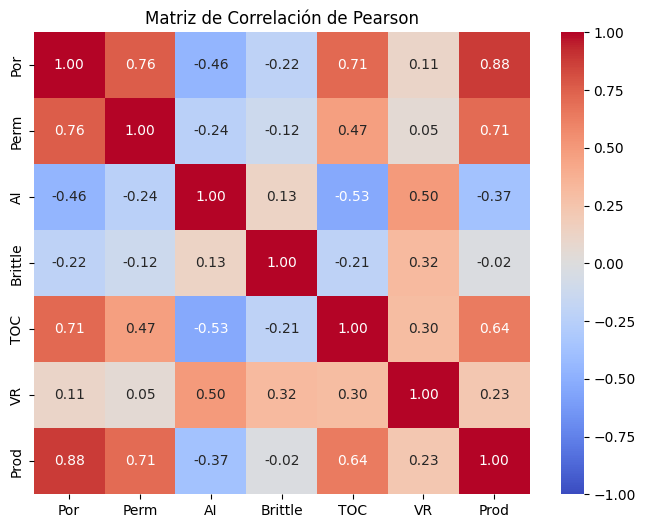

Correlación absoluta con 'Prod':
Por        0.881555
Perm       0.705222
TOC        0.638357
AI         0.367237
VR         0.230806
Brittle    0.021095
Name: Prod, dtype: float64

La variable con mayor relación lineal con la producción es: 'Por'


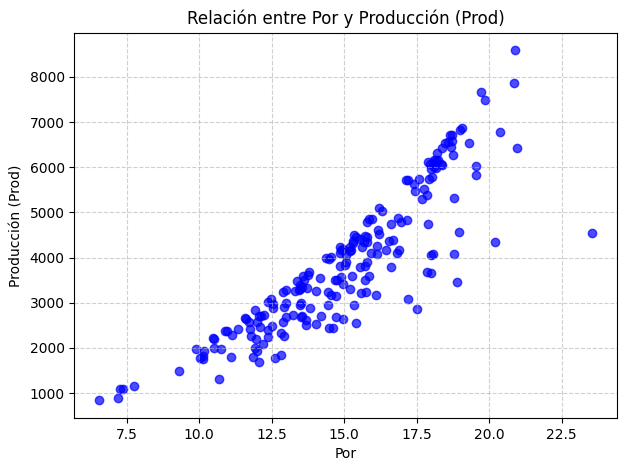

In [ ]:
# Cálculo de la matriz de correlación
plt.figure(figsize=(8, 6))
corr_matrix = df[features_6 + [target]].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title("Matriz de Correlación de Pearson")
plt.show()

# Identificar la variable más correlacionada con Prod
corr_with_target = corr_matrix[target].drop(target).abs().sort_values(ascending=False)
print("Correlación absoluta con 'Prod':")
print(corr_with_target)

best_feature = corr_with_target.index[0]
print(f"\nLa variable con mayor relación lineal con la producción es: '{best_feature}'")

# Diagrama de dispersión de la mejor variable vs Prod
plt.figure(figsize=(7, 5))
plt.scatter(df[best_feature], df[target], alpha=0.7, color='blue')
plt.xlabel(best_feature)
plt.ylabel('Producción (Prod)')
plt.title(f'Relación entre {best_feature} y Producción (Prod)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## Actividad: Regresión Polinomial ##
La Regresión Polinomial extiende la regresión lineal expresando la variable de respuesta $\hat{y}$ como una combinación lineal de las potencias de las variables predictoras:

$$\hat{y} = b_0 + \sum_{l=1}^{d} \sum_{j=1}^{m} b_{j,l} \cdot h_l(X_j)$$

donde $h_l(X_j) = X_j^l$ representa la potencia de grado l para la variable j, y d es el grado máximo del polinomio. En forma reducida y extendida con términos de interacción multidimensionales:
$$\hat{y} = b_0 + b_{1,1}X_1 + b_{2,1}X_2 + \dots + b_{1,2}X_1^2 + b_{2,2}X_2^2 + \dots$$

Evaluación con las 6 variables
Ejecutamos el entrenamiento polinomial utilizando las 6 variables estandarizadas y evaluamos con las métricas (MAE, MSE, RMSE, R^2).

In [ ]:
# Grado del polinomio
degree_p1 = 2

# Transformación polinomial de 6 variables
poly_6 = PolynomialFeatures(degree=degree_p1, include_bias=False)
X_6_poly = poly_6.fit_transform(X_6_scaled)

# Ajuste del modelo de regresión lineal
model_p1 = LinearRegression()
model_p1.fit(X_6_poly, y)
y_pred_p1 = model_p1.predict(X_6_poly)

# Métricas de evaluación
mae_p1 = mean_absolute_error(y, y_pred_p1)
mse_p1 = mean_squared_error(y, y_pred_p1)
rmse_p1 = np.sqrt(mse_p1)
r2_p1 = r2_score(y, y_pred_p1)

print("=== RESULTADOS (6 variables, Grado 2) ===")
print(f"Número de coeficientes/características generadas: {X_6_poly.shape[1]}")
print(f"MAE  : {mae_p1:.4f}")
print(f"MSE  : {mse_p1:.4f}")
print(f"RMSE : {rmse_p1:.4f}")
print(f"R²   : {r2_p1:.4f}")

=== RESULTADOS (6 variables, Grado 2) ===
Número de coeficientes/características generadas: 27
MAE  : 212.5343
MSE  : 96467.5269
RMSE : 310.5922
R²   : 0.9598


###¿Por qué Scikit-Learn genera más coeficientes de los que debería? ###
Con 2 variables ($x_1, x_2$) y grado d=8, teóricamente un cálculo simple de términos puros da $2 \times 8 = 16$ términos. Sin embargo, la función PolynomialFeatures de Scikit-Learn genera 36 características, debido a que incluye todos los términos de interacción cruzada.  
La fórmula para determinar el número de términos generados con m variables de entrada hasta grado d es:
$$N = \binom{m + d}{d} - 1 = \frac{(m + d)!}{m! \cdot d!} - 1$$

Para m=2 variables (Por, Perm) y grado d=8:
$$N = \frac{(2 + 8)!}{2! \cdot 8!} - 1 = \frac{10 \times 9}{2} - 1 = 45 - 1 = 44$$

Si la opción $include\_bias=False$, la cantidad de coeficientes generados para la regresión es 36, correspondiente a combinaciones como $x_1^a x_2^b$ tales que $1 \le a + b \le 8$.

##Definimos el hiperparametro ##
El hiperparámetro $\alpha$ (denotado como $\lambda$ en la teoría matemática) regula la intensidad de la penalización $L_2$ en la regresión Ridge. La función de pérdida que minimiza el modelo es:
$$\text{Loss}_{\text{Ridge}} = \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 + \alpha \sum_{j=1}^{p} \beta_j^2$$

Si $\alpha = 0$: No existe penalización; el modelo equivale a una regresión lineal por mínimos cuadrados ordinarios.  
Si $\alpha \to \infty$: La penalización se vuelve muy fuerte y los coeficientes se contraen hacia cero ($\beta_j \to 0$), lo que incrementa el sesgo y reduce la varianza.

In [ ]:
# Definir y estandarizar las 2 variables con más relación (Por y Perm)
features_2 = ['Por', 'Perm']
scaler_2 = StandardScaler()
X_2_scaled = scaler_2.fit_transform(df[features_2])

# Demostración del efecto del hiperparámetro Alpha (Ridge) sobre la Regresión Polinomial de Grado Alto
degree_high = 4
poly_high = PolynomialFeatures(degree=degree_high, include_bias=False)
X_high_poly = poly_high.fit_transform(X_2_scaled)

alphas = [0.0, 0.1, 10.0, 1000.0]
coef_magnitudes = []

for a in alphas:
    if a == 0:
        model_ridge = LinearRegression()
    else:
        model_ridge = Ridge(alpha=a)

    model_ridge.fit(X_high_poly, y)
    coef_magnitudes.append(np.linalg.norm(model_ridge.coef_))
    print(f"Alpha = {a:<6} | Norma de coeficientes (||w||): {np.linalg.norm(model_ridge.coef_):.4f} | R²: {r2_score(y, model_ridge.predict(X_high_poly)):.4f}")

Alpha = 0.0    | Norma de coeficientes (||w||): 2687.8186 | R²: 0.8336
Alpha = 0.1    | Norma de coeficientes (||w||): 2308.4550 | R²: 0.8334
Alpha = 10.0   | Norma de coeficientes (||w||): 1374.4824 | R²: 0.8224
Alpha = 1000.0 | Norma de coeficientes (||w||): 195.6073 | R²: 0.4901


##Predicción ##
A continuación, utilizamos el modelo polinomial para predecir la producción de un nuevo pozo hipotético cuyas propiedades petrofísicas son conocidas.

In [ ]:
# Ejemplo de entrada de un pozo hipotético:
# Por=15.0, Perm=2.5, AI=3.0, Brittle=45.0, TOC=2.0, VR=1.8
pozo_nuevo_df = pd.DataFrame([[15.0, 2.5, 3.0, 45.0, 2.0, 1.8]], columns=features_6)

# 1. Normalizar usando el scaler ajustado previamente
pozo_nuevo_scaled = scaler.fit(df[features_6]).transform(pozo_nuevo_df)

# 2. Transformar a características polinomiales
pozo_nuevo_poly = poly_6.transform(pozo_nuevo_scaled)

# 3. Realizar la predicción con el modelo de 6 variables
prediccion_prod = model_p1.predict(pozo_nuevo_poly)

print("=== PREDICCIÓN PARA NUEVAS CONDICIONES ===")
print(pozo_nuevo_df.to_string(index=False))
print(f"\nProducción estimada (Prod): {prediccion_prod[0]:.2f} BPD")

=== PREDICCIÓN PARA NUEVAS CONDICIONES ===
 Por  Perm  AI  Brittle  TOC  VR
15.0   2.5 3.0     45.0  2.0 1.8

Producción estimada (Prod): 3993.97 BPD


##Conclusiones y Reflexión Técnica ##
•Efecto de la Dimensionalidad en Regresión Polinomial: La inclusión de las 6 variables independientes en un grado polinomial ofrece mayor capacidad explicativa ($R^2$ superior) en comparación con el modelo restringido únicamente a Por y Perm, debido a la complejidad física multidimensional del yacimiento.  
• Generación de Términos por Scikit-Learn: Comprobamos que PolynomialFeatures no solo calcula las potencias individuales de cada variable ($X_j^d$), sino que genera el espacio factorial completo de interacciones cruzadas ($X_1^a X_2^b$), incrementando el número de coeficientes de forma exponencial conforme aumenta el grado.  
•Control del Sobreajuste mediante Alpha: El empleo de hiperparámetros de regularización como $\alpha$ (Ridge) es fundamental en modelos polinomiales de grado elevado. Evita que el modelo asigne coeficientes desmedidos o inestables ante variables correlacionadas, logrando un mejor equilibrio entre el sesgo y la varianza.

BIBLIOGRAFÍA

•Ahmed, T. (2018). Reservoir Engineering Handbook (5th ed.). Gulf Professional Publishing.

•James, G., Witten, D., Hastie, T., & Tibshirani, R. (2013). An Introduction to Statistical Learning with Applications in R. Springer. (Capítulo 6: Linear Model Selection and Regularization).

•Hastie, T., Tibshirani, R., & Friedman, J. (2009). The Elements of Statistical Learning. Springer.